# Анализ и прогнозирование временных рядов методами искусственного интеллекта
## Артемьев М.О. ЕТ-228
## **Практическая работа 6. Поиск эволюционирующих шаблонов с помощью матричного профиля ряда.**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys

practice_dir_path = '/content/drive/MyDrive/06 Chains'

os.chdir(practice_dir_path)

if practice_dir_path not in sys.path:
    sys.path.insert(0, practice_dir_path)

print("Рабочая папка:", os.getcwd())
print("Файлы:", os.listdir())
print("Файл данных найден:",
      os.path.isfile('datasets/Rotation Matrix.txt'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Рабочая папка: /content/drive/MyDrive/06 Chains
Файлы: ['06 Chains', 'datasets']
Файл данных найден: True


In [ ]:
%load_ext autoreload
%autoreload 2

## **Часть 1.** Поиск цепочек временного ряда.

Импорт библиотек и модулей

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.metrics import mean_squared_error

В первом задании вам предстоит выполнить поиск эволюционирующих шаблонов временного ряда. Выполните считывание набора данных [Rotation Matrix](datasets/Rotation%20Matrix.txt), найдите в нем самую длинную цепочку и выведите индексы начала звеньев этой цепочки.

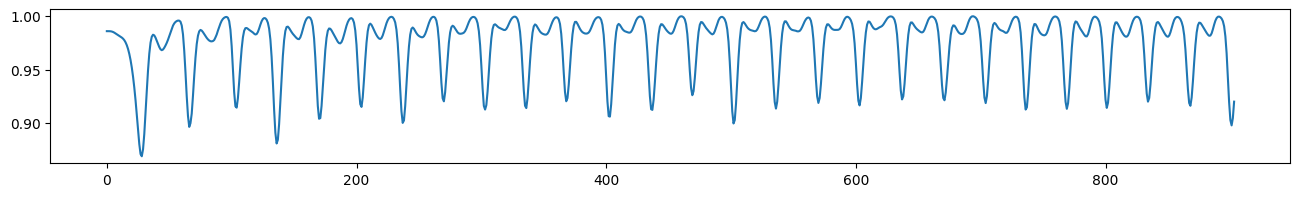

In [ ]:
fig, ax = plt.subplots(figsize=(16, 2))
ts = np.loadtxt('datasets/Rotation Matrix.txt')
ax.plot(ts)

In [ ]:
# INSERT YOUR CODE
ts = np.loadtxt('datasets/Rotation Matrix.txt')
m = 30
mp = stumpy.stump(ts, m=m)
all_chains, longest_chain = stumpy.allc(mp.left_I_, mp.right_I_)

print("Длина временного ряда:", len(ts))
print("Длина подпоследовательности:", m)
print("Количество звеньев в самой длинной цепочке:", len(longest_chain))
print("Индексы начала звеньев:", longest_chain)

Длина временного ряда: 904
Длина подпоследовательности: 30
Количество звеньев в самой длинной цепочке: 5
Индексы начала звеньев: [144 376 410 644 841]


❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Для временного ряда длиной 904 значения при длине подпоследовательности 30 найдена самая длинная цепочка из 5 звеньев. Индексы начала звеньев, 144, 376, 410, 644 и 841.

Каждое звено представляет собой подпоследовательность из 30 последовательных значений. Соседние звенья связаны взаимным отношением ближайших соседей,следующее звено является ближайшим правым соседом предыдущего, а предыдущее является ближайшим левым соседом следующего.

Полученная цепочка описывает последовательность похожих шаблонов, форма которых может постепенно изменяться. Звенья расположены в порядке возрастания времени, но интервалы между их началами различаются.

## **Часть 2. Визуализация цепочек**

Выполните визуализацию найденных в прошлом задании цепочек: постройте график временного ряда, на котором выделены звенья цепочек. Также постройте график, на котором изображены только сами звенья.

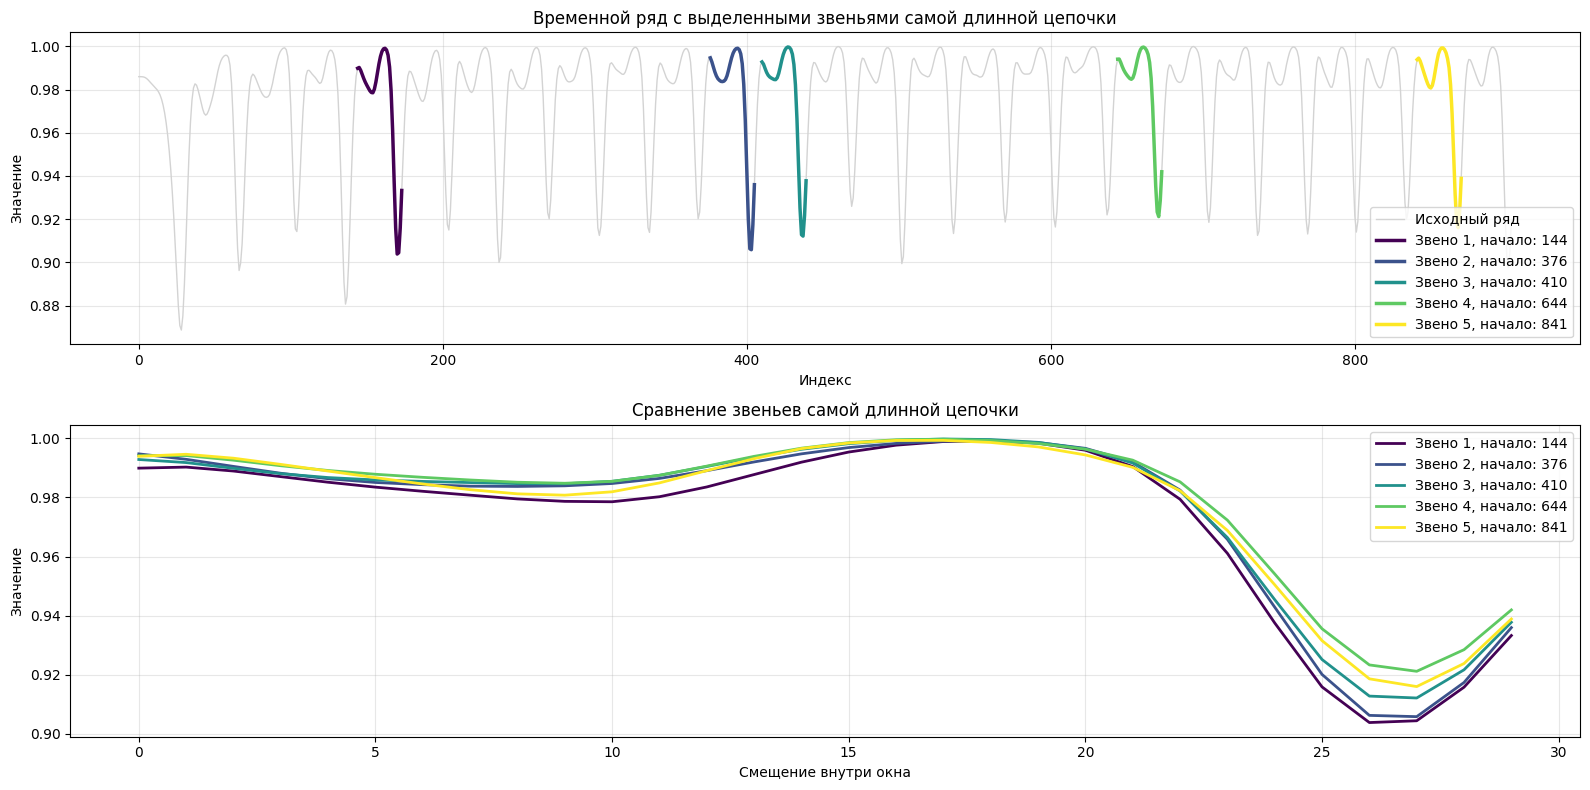

In [ ]:
colors = plt.cm.viridis(np.linspace(0, 1, len(longest_chain)))

fig, axes = plt.subplots(2, 1, figsize=(16, 8))

axes[0].plot(ts, color='lightgray', linewidth=1, label='Исходный ряд')

for i, start in enumerate(longest_chain):
    axes[0].plot(
        np.arange(start, start + m),
        ts[start:start + m],
        color=colors[i],
        linewidth=2.5,
        label=f'Звено {i + 1}, начало: {start}'
    )

axes[0].set_title('Временной ряд с выделенными звеньями самой длинной цепочки')
axes[0].set_xlabel('Индекс')
axes[0].set_ylabel('Значение')
axes[0].legend()
axes[0].grid(alpha=0.3)

for i, start in enumerate(longest_chain):
    axes[1].plot(
        np.arange(m),
        ts[start:start + m],
        color=colors[i],
        linewidth=2,
        label=f'Звено {i + 1}, начало: {start}'
    )

axes[1].set_title('Сравнение звеньев самой длинной цепочки')
axes[1].set_xlabel('Смещение внутри окна')
axes[1].set_ylabel('Значение')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

На первом графике показано расположение пяти звеньев самой длинной цепочки во временном ряду. Подпоследовательности следуют в порядке возрастания времени, но расстояния между их началами различаются.

На втором графике звенья совмещены по началу окна. Видно, что они имеют похожую форму, небольшое снижение, подъем до значения около 1, затем резкий спад и частичное восстановление. Основные различия наблюдаются в глубине минимума в конце окна.

От первого к четвертому звену этот минимум становится менее глубоким, однако у пятого звена он снова немного снижается. Следовательно, изменение шаблона не является строго монотонным. Найденная цепочка отражает эволюцию похожих подпоследовательностей, которые сохраняют общую форму, но различаются отдельными значениями.

## **Часть 3.** Предсказывание значений ряда на основе цепочек.

Предскажите значения последнего звена цепочки, вычислив разность между двумя предыдущими звеньями цепочки. Сравните полученное предсказание с истинным значением.

Начала звеньев для прогноза: 410 644
Начало предсказываемого звена: 841
Средняя квадратичная ошибка (MSE): 0.00004137
Корень средней квадратичной ошибки (RMSE): 0.006432


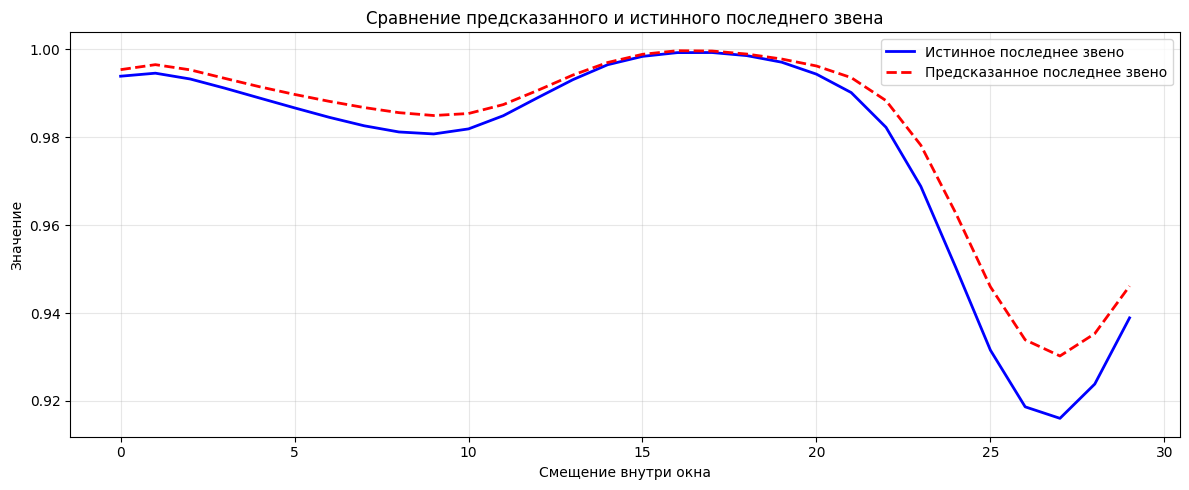

In [ ]:
# INSERT YOUR CODE
idx_prev2, idx_prev1, idx_last = longest_chain[-3:]

prev2 = ts[idx_prev2:idx_prev2 + m]
prev1 = ts[idx_prev1:idx_prev1 + m]

y_true = ts[idx_last:idx_last + m]

difference = prev1 - prev2
y_pred = prev1 + difference

mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

print("Начала звеньев для прогноза:", idx_prev2, idx_prev1)
print("Начало предсказываемого звена:", idx_last)
print(f"Средняя квадратичная ошибка (MSE): {mse:.8f}")
print(f"Корень средней квадратичной ошибки (RMSE): {rmse:.6f}")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    np.arange(m), y_true,
    color='blue', linewidth=2,
    label='Истинное последнее звено'
)
ax.plot(
    np.arange(m), y_pred,
    color='red', linestyle='--', linewidth=2,
    label='Предсказанное последнее звено'
)

ax.set_title('Сравнение предсказанного и истинного последнего звена')
ax.set_xlabel('Смещение внутри окна')
ax.set_ylabel('Значение')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Прогноз последнего звена получен путем прибавления к предыдущему звену разности между двумя предыдущими подпоследовательностями. Такой подход предполагает, что изменение формы шаблона сохранится при переходе к следующему звену.

На графике видно, что прогноз воспроизводит общую форму истинной подпоследовательности, небольшое снижение, подъем к максимуму, резкий спад и последующее восстановление. В области максимума линии практически совпадают. Однако на большей части окна предсказанные значения выше истинных.

Наибольшее расхождение наблюдается около смещения 27, истинное значение составляет примерно 0,916, а прогнозное около 0,930. Метод предсказывает менее глубокий минимум, поскольку продолжает тенденцию его повышения между двумя предыдущими звеньями. В последнем звене направление этого изменения меняется.

Таким образом, метод позволяет приблизительно предсказать форму последнего звена, но не полностью передает глубину его минимума. Точность прогноза зависит от того, насколько устойчиво сохраняется характер изменения соседних звеньев цепочки.